Daily observations: 366
Date range: 2021-09-30 00:00:00 to 2022-09-30 00:00:00


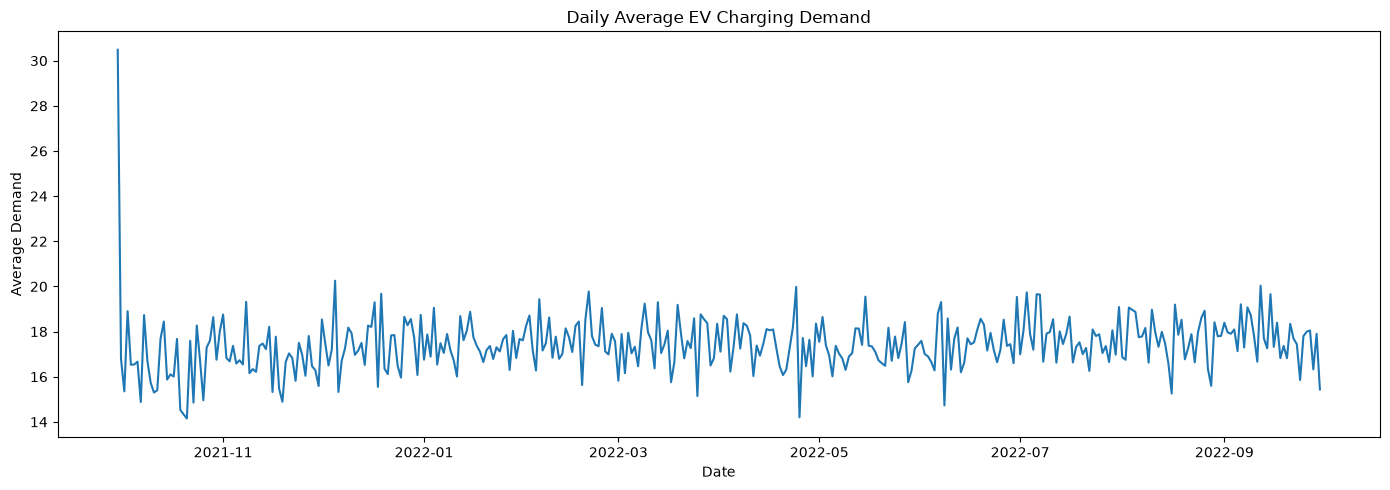

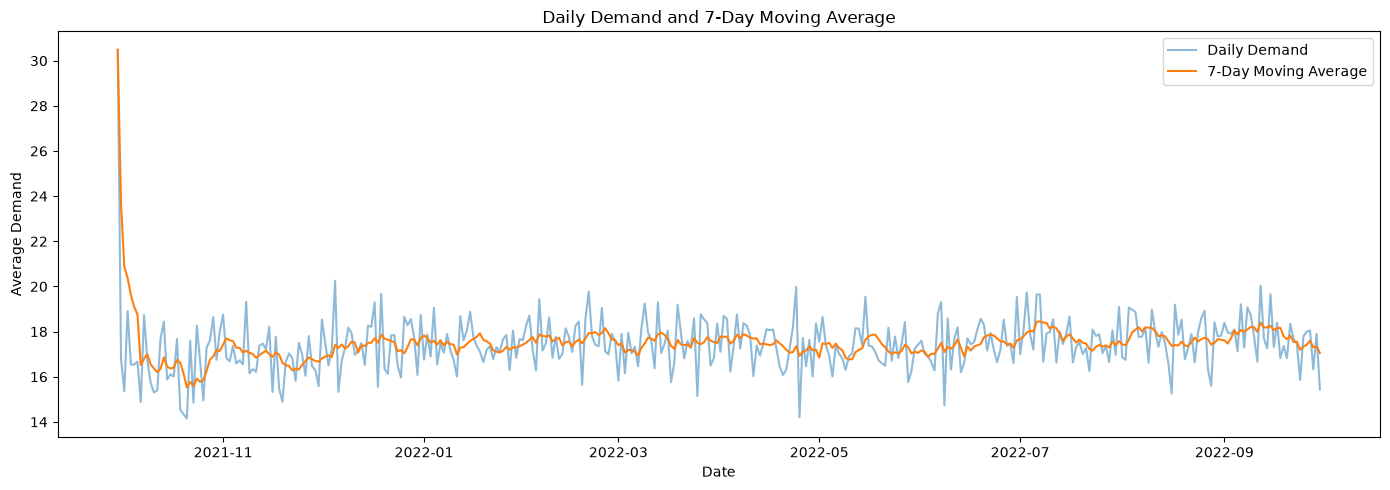

Training observations: 292
Testing observations: 74

FORECAST MODEL COMPARISON
                Model    MAE   RMSE
 7-Day Moving Average 0.7789 0.9765
Exponential Smoothing 0.7503 0.9676
ADF statistic: -5.1609
p-value: 1.0562519477438115e-05

AUGMENTED DICKEY-FULLER TEST
ADF statistic: -5.1609
p-value: 0.0
Result: Evidence of stationarity at the 5% level.


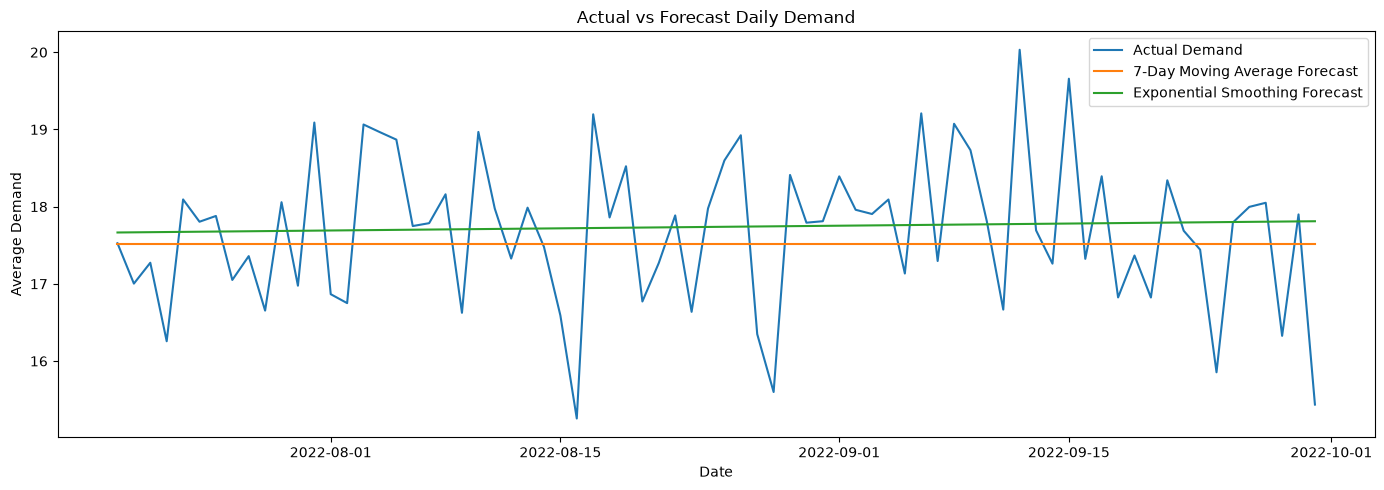


TIME SERIES FORECASTING COMPLETED!


In [4]:

# ==========================================
# EV CHARGING DEMAND - TIME SERIES FORECASTING
# ==========================================


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller

# STEP 1: LOAD CLEANED DATA
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "ChargingRecords_Cleaned.csv"
)

df = pd.read_csv(DATA_PATH)
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="coerce"
)

df = df.dropna(subset=["StartDatetime", "Demand"])

# STEP 2: AGGREGATE DEMAND BY DAY
daily_demand = (
    df.set_index("StartDatetime")["Demand"]
      .resample("D")
      .mean()
      .dropna()
)

print("Daily observations:", len(daily_demand))
print("Date range:", daily_demand.index.min(), "to",
      daily_demand.index.max())

# STEP 3: VISUALIZE DAILY DEMAND
plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Daily Average EV Charging Demand")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

# STEP 4: CHECK TREND WITH A MOVING AVERAGE
daily_demand_ma = daily_demand.rolling(
    window=7, min_periods=1
).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values,
         label="Daily Demand", alpha=0.5)
plt.plot(daily_demand_ma.index, daily_demand_ma.values,
         label="7-Day Moving Average")
plt.title("Daily Demand and 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 5: TRAIN / TEST SPLIT IN TIME ORDER
split_point = int(len(daily_demand) * 0.80)

train = daily_demand.iloc[:split_point]
test = daily_demand.iloc[split_point:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

# STEP 6: MOVING-AVERAGE FORECAST
window = 7
moving_average_value = train.tail(window).mean()

moving_average_forecast = np.full(
    len(test), moving_average_value
)

# STEP 7: EXPONENTIAL SMOOTHING FORECAST
ets_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
).fit()

ets_forecast = ets_model.forecast(len(test))

# STEP 8: EVALUATE FORECASTS
def evaluate_forecast(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mse)
    }

forecast_results = pd.DataFrame([
    evaluate_forecast(
        "7-Day Moving Average", test, moving_average_forecast
    ),
    evaluate_forecast(
        "Exponential Smoothing", test, ets_forecast
    )
])

print("\nFORECAST MODEL COMPARISON")
print(forecast_results.round(4).to_string(index=False))

# STEP 9: STATIONARITY TEST
#adf_result = adfuller(daily_demand)
adf_result = adfuller(daily_demand, result_object=True)
print("ADF statistic:", round(adf_result.statistic, 4))
print("p-value:", adf_result.pvalue)

print("\nAUGMENTED DICKEY-FULLER TEST")
print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print("Result: Evidence of stationarity at the 5% level.")
else:
    print("Result: Insufficient evidence of stationarity at the 5% level.")

# STEP 10: PLOT TEST FORECASTS
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, label="Actual Demand")
plt.plot(test.index, moving_average_forecast,
         label="7-Day Moving Average Forecast")
plt.plot(test.index, ets_forecast.values,
         label="Exponential Smoothing Forecast")
plt.title("Actual vs Forecast Daily Demand")
plt.xlabel("Date")
plt.ylabel("Average Demand")
plt.legend()
plt.tight_layout()
plt.show()

print("\nTIME SERIES FORECASTING COMPLETED!")